#### Prompt Chaining
- ***Prompt Chaining is the process of breaking a complex LLM task into a sequence of smaller prompts, where the output of one prompt becomes the input to the next.***

- ***This improves accuracy, modularity, maintainability, and makes AI workflows easier to debug and extend. It is a foundational pattern in frameworks like LangChain and LangGraph.***

In [1]:
import warnings
warnings.filterwarnings("ignore")

from langgraph.graph import StateGraph,START,END 
from langchain_groq import ChatGroq
from typing import TypedDict 

from dotenv import load_dotenv
load_dotenv()

# Define Our Model
llm = ChatGroq(
    model="openai/gpt-oss-120b",
    temperature=0
)

In [2]:
## Define State 
class Blog_State(TypedDict):
    title:str 
    outline:str
    content:str

## Creating Node 
def create_outline(state: Blog_State) -> Blog_State:
    # fetch title
    title = state['title']

    # call llm gen outline
    prompt = f'Generate a detailed outline for a blog on the topic : {title}'
    outline = llm.invoke(prompt).content

    # update state
    state['outline'] = outline

    return state

def create_blog(state: Blog_State) -> Blog_State:
    title = state['title']
    outline = state['outline']

    prompt = f'Write a detailed blog on the title - {title} using the follwing outline \n {outline}'
    content = llm.invoke(prompt).content
    state['content'] = content

    return state

In [3]:
## Define & Compile Graph 
graph = StateGraph(Blog_State)

graph.add_node('create_outline', create_outline)
graph.add_node('create_blog', create_blog)

graph.add_edge(START, 'create_outline')
graph.add_edge('create_outline', 'create_blog')
graph.add_edge('create_blog', END)

workflow = graph.compile()

In [8]:
## Execute Graph 
intial_state = {'title': 'Rise of AI in India & Future of AIML Engineer'}
final_state = workflow.invoke(intial_state)
print(final_state)

{'title': 'Rise of AI in India & Future of AIML Engineer', 'outline': '**Blog Title:**  \n*The Rise of AI in India & What the Future Holds for the AIML Engineer*\n\n---\n\n## 1. Introduction  \n- **Hook:** A striking statistic or anecdote (e.g., “India’s AI market is projected to hit $17\u202fbillion by 2027”)  \n- **Why it matters:** The strategic importance of AI for India’s economy, society, and global tech standing.  \n- **Purpose of the post:**  \n  - Trace the evolution of AI in India.  \n  - Highlight key drivers and milestones.  \n  - Explore the emerging career path of the **AIML (Artificial Intelligence & Machine Learning) Engineer**.  \n  - Offer actionable insights for students, professionals, and policymakers.\n\n---\n\n## 2. The Evolution of AI in India – A Chronological Snapshot  \n\n| Period | Milestones & Events | Impact |\n|--------|--------------------|--------|\n| **Pre‑2010** | • Early research labs at IITs & IISc <br>• Government’s “Technology Vision 2020” (2005) 

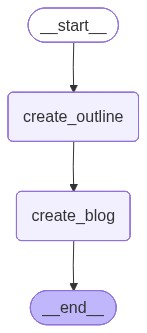

In [9]:
## Visualize Out Graph 
from IPython.display import Image
Image(workflow.get_graph().draw_mermaid_png())